# Трендовая кластеризация временных рядов: примеры и эксперименты

Ноутбук воспроизводит рисунки 3–5 и таблицы 1–2 статьи о библиотеке
[pytrendclust](https://pypi.org/project/pytrendclust/)
([исходный код](https://github.com/89605502155/pytrendclust)).
Все ряды генерируются с фиксированными зёрнами генератора, поэтому
результаты совпадают при каждом запуске.

Запуск: `uv run jupyter nbconvert --to notebook --execute --inplace examples.ipynb`

In [1]:
import io
import math
import time
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Polygon
from PIL import Image

import pytrendclust
from pytrendclust import Trend, cluster_trends

print("pytrendclust", pytrendclust.__version__)
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

pytrendclust 0.2.0


## Оформление рисунков

Ширина рисунка 17 см равна ширине печатного поля журнала, шрифт 12 pt,
разрешение 600 dpi. Поля вокруг рисунка обрезаются по содержимому с
небольшим зазором, чтобы подписи осей не срезались.

In [2]:
CM = 1 / 2.54
mpl.rcParams.update({
    "font.family": "Times New Roman",
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.linewidth": 0.9,
})
COLORS = {Trend.UP: "#2E9E44", Trend.DOWN: "#D7263D", Trend.FLAT: "#2B6CB0"}
NAMES = {Trend.UP: "рост", Trend.DOWN: "спад", Trend.FLAT: "плато"}
ALPHA = 0.34


def cluster_ellipse(ax, t, y, pad_px=14.0, min_half_px=16.0, n=240):
    """Эллипс, охватывающий точки кластера, в координатах данных.

    Строится в экранных координатах по главным осям облака точек, поэтому
    не искажается разным масштабом осей, затем переводится в координаты данных.
    """
    pts = ax.transData.transform(np.column_stack([t, y]))
    centre = pts.mean(axis=0)
    if len(pts) > 1:
        _, _, vt = np.linalg.svd(pts - centre, full_matrices=False)
        e1 = vt[0]
    else:
        e1 = np.array([1.0, 0.0])
    e2 = np.array([-e1[1], e1[0]])
    u, v = (pts - centre) @ e1, (pts - centre) @ e2
    centre = centre + e1 * (u.max() + u.min()) / 2 + e2 * (v.max() + v.min()) / 2
    u, v = (pts - centre) @ e1, (pts - centre) @ e2
    a = max(np.abs(u).max(), min_half_px)
    b = max(np.abs(v).max(), min_half_px)
    s = np.sqrt((u / a) ** 2 + (v / b) ** 2).max()   # растяжение до охвата всех точек
    a, b = a * max(s, 1.0) + pad_px, b * max(s, 1.0) + pad_px
    phi = np.linspace(0, 2 * np.pi, n)
    ring = centre + np.outer(a * np.cos(phi), e1) + np.outer(b * np.sin(phi), e2)
    return ax.transData.inverted().transform(ring)


TARGET_MM = 170.0   # ширина готового рисунка = ширина печатного поля


def plot_clusters(result, path, height_cm=6.8, **labels):
    """Рисует кластеры и подбирает ширину холста так, чтобы после обрезки
    полей рисунок имел ширину ровно 170 мм и шрифт не масштабировался."""
    width_cm = 17.0
    for _ in range(6):
        fig = draw_clusters(result, width_cm, height_cm, **labels)
        buf = io.BytesIO()
        fig.savefig(buf, format="png", dpi=600, bbox_inches="tight", pad_inches=0.04)
        with Image.open(buf) as im:
            got_mm = im.size[0] / 600 * 25.4
        if abs(got_mm - TARGET_MM) < 0.3:
            break
        plt.close(fig)
        width_cm += (TARGET_MM - got_mm) / 10
    for ext in ("png", "tif"):
        fig.savefig(FIG_DIR / f"{path}.{ext}", dpi=600, bbox_inches="tight",
                    pad_inches=0.04, facecolor="white",
                    **({"pil_kwargs": {"compression": "tiff_lzw"}} if ext == "tif" else {}))
    plt.show()
    plt.close(fig)
    with Image.open(FIG_DIR / f"{path}.png") as im:
        print(f"{path}: {im.size[0]}x{im.size[1]} px, "
              f"{im.size[0] / 600 * 25.4:.1f}x{im.size[1] / 600 * 25.4:.1f} мм")


def clip_vertical(ring, x_min=-np.inf, x_max=np.inf):
    """Обрезает выпуклый многоугольник вертикальными прямыми x = x_min и x = x_max."""
    def clip(poly, inside, cross):
        out = []
        for a, b in zip(poly, np.roll(poly, -1, axis=0)):
            if inside(b):
                if not inside(a):
                    out.append(cross(a, b))
                out.append(b)
            elif inside(a):
                out.append(cross(a, b))
        return np.array(out)

    def at_x(x0):
        return lambda a, b: a + (b - a) * (x0 - a[0]) / (b[0] - a[0])

    ring = clip(ring, lambda p: p[0] >= x_min, at_x(x_min)) if np.isfinite(x_min) else ring
    ring = clip(ring, lambda p: p[0] <= x_max, at_x(x_max)) if np.isfinite(x_max) else ring
    return ring


def boundary_points(result):
    """Индексы точек разладки, общих для соседних кластеров.

    Из двух соседних отсчётов на границе кластеров выбирается тот, в котором
    меняется монотонность: минимум при переходе «спад -> рост», максимум при
    переходе «рост -> спад», иначе первый отсчёт нового кластера.
    """
    y = result.y
    points = []
    for a, b in zip(result.segments, result.segments[1:]):
        i, j = b.start - 1, b.start
        if a.trend is Trend.DOWN and b.trend is Trend.UP:
            points.append(i if y[i] <= y[j] else j)
        elif a.trend is Trend.UP and b.trend is Trend.DOWN:
            points.append(i if y[i] >= y[j] else j)
        else:
            points.append(j)
    return points


def cluster_regions(ax, result, gap):
    """Области кластеров: эллипсы, обрезанные по обе стороны от точек разладки.

    Точка разладки принадлежит обоим соседним кластерам, поэтому области
    обрезаются вертикальными прямыми на расстоянии gap слева и справа от неё:
    области соседних кластеров не пересекаются, а точка разладки лежит между ними.
    """
    t, y = result.t, result.y
    cps = boundary_points(result)
    regions = []
    for k, s in enumerate(result.segments):
        ring = cluster_ellipse(ax, t[s.start:s.stop], y[s.start:s.stop])
        left = t[cps[k - 1]] + gap if k > 0 else -np.inf
        right = t[cps[k]] - gap if k < len(cps) else np.inf
        regions.append(clip_vertical(ring, left, right))
    return regions, cps


def draw_clusters(result, width_cm, height_cm, xlabel="Номер отсчёта $t$",
                  ylabel="Значение $y$"):
    fig, ax = plt.subplots(figsize=(width_cm * CM, height_cm * CM), dpi=600)
    t, y = result.t, result.y
    ax.plot(t, y, color="0.35", linewidth=0.8, zorder=3)
    ax.scatter(t, y, s=10, color="black", zorder=4, linewidths=0)
    ax.grid(True, linestyle="--", color="grey", alpha=0.45, linewidth=0.7)
    ax.set_axisbelow(True)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    gap_min = 0.3 * float(np.min(np.diff(t))) if len(t) > 1 else 0.0

    # пределы осей подбираются так, чтобы области целиком помещались в рамку
    xr, yr = np.ptp(t), np.ptp(y) or 1.0
    xpad, ypad = 0.03 * xr, 0.12 * yr
    for _ in range(10):
        ax.set_xlim(t.min() - xpad, t.max() + xpad)
        ax.set_ylim(y.min() - ypad, y.max() + ypad)
        fig.canvas.draw()
        # зазор между областями: не меньше 0,7 мм на бумаге
        px_per_unit = abs(ax.transData.transform([(1, 0)])[0, 0]
                          - ax.transData.transform([(0, 0)])[0, 0])
        gap = max(gap_min, 0.8 / 25.4 * fig.dpi / px_per_unit)
        regions, bounds = cluster_regions(ax, result, gap)
        allr = np.vstack(regions)
        (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
        if (allr[:, 0].min() >= x0 and allr[:, 0].max() <= x1
                and allr[:, 1].min() >= y0 and allr[:, 1].max() <= y1):
            break
        xpad *= 1.25
        ypad *= 1.25
    else:
        raise RuntimeError("области кластеров не помещаются в область графика")

    for s, ring in zip(result.segments, regions):
        colour = COLORS[s.trend]
        ax.add_patch(Polygon(ring, closed=True, facecolor=colour, alpha=ALPHA,
                             edgecolor="none", zorder=1))
        ax.add_patch(Polygon(ring, closed=True, facecolor="none", edgecolor=colour,
                             linewidth=1.1, alpha=0.9, zorder=2))

    # точки разладки: звезда на самой точке, пунктир и указатель с номером отсчёта
    for i in bounds:
        ax.axvline(t[i], color="black", linestyle=(0, (4, 2)), linewidth=0.9, zorder=2.5)
        ax.plot([t[i]], [y[i]], marker="*", markersize=15, markerfacecolor="#FFD43B",
                markeredgecolor="black", markeredgewidth=0.9, zorder=6, linestyle="none")
        ax.plot([t[i]], [1.0], marker="v", markersize=7, color="black", clip_on=False,
                transform=ax.get_xaxis_transform(), zorder=5)
        ax.annotate(f"{int(t[i])}", xy=(t[i], 1.0), xycoords=("data", "axes fraction"),
                    xytext=(0, 7), textcoords="offset points", ha="center", va="bottom",
                    fontsize=11, annotation_clip=False)

    used = [tr for tr in (Trend.DOWN, Trend.UP, Trend.FLAT)
            if any(s.trend is tr for s in result.segments)]
    handles = [Patch(facecolor=COLORS[tr], alpha=ALPHA, edgecolor=COLORS[tr],
                     label=NAMES[tr]) for tr in used]
    if bounds:
        handles.append(Line2D([0], [0], color="black", linestyle=(0, (4, 2)), linewidth=0.9,
                              marker="*", markersize=13, markerfacecolor="#FFD43B",
                              markeredgecolor="black", label="точка разладки"))
    else:
        handles.append(Line2D([0], [0], color="none", label="точек разладки нет"))
    ax.legend(handles=handles, loc="lower center",
              bbox_to_anchor=(0.5, 1.09 if bounds else 1.0), ncol=len(handles),
              frameon=False, handlelength=1.8, borderaxespad=0.3)
    return fig

## Рисунок 3. Зашумлённая парабола

Ряд из 60 отсчётов $y_t = 0{,}05\,(t-35)^2 + \varepsilon_t$, $\varepsilon_t \sim N(0, 1)$.
У ряда одна смена монотонности, в вершине параболы.

60 points, 1 change point(s), noise std 0.9952
  #0: [0, 32)   32 pts  down  slope -1.975
  #1: [32, 60)   28 pts  up    slope +1.076
точки разладки: [32]
линейных кусков до объединения: 4


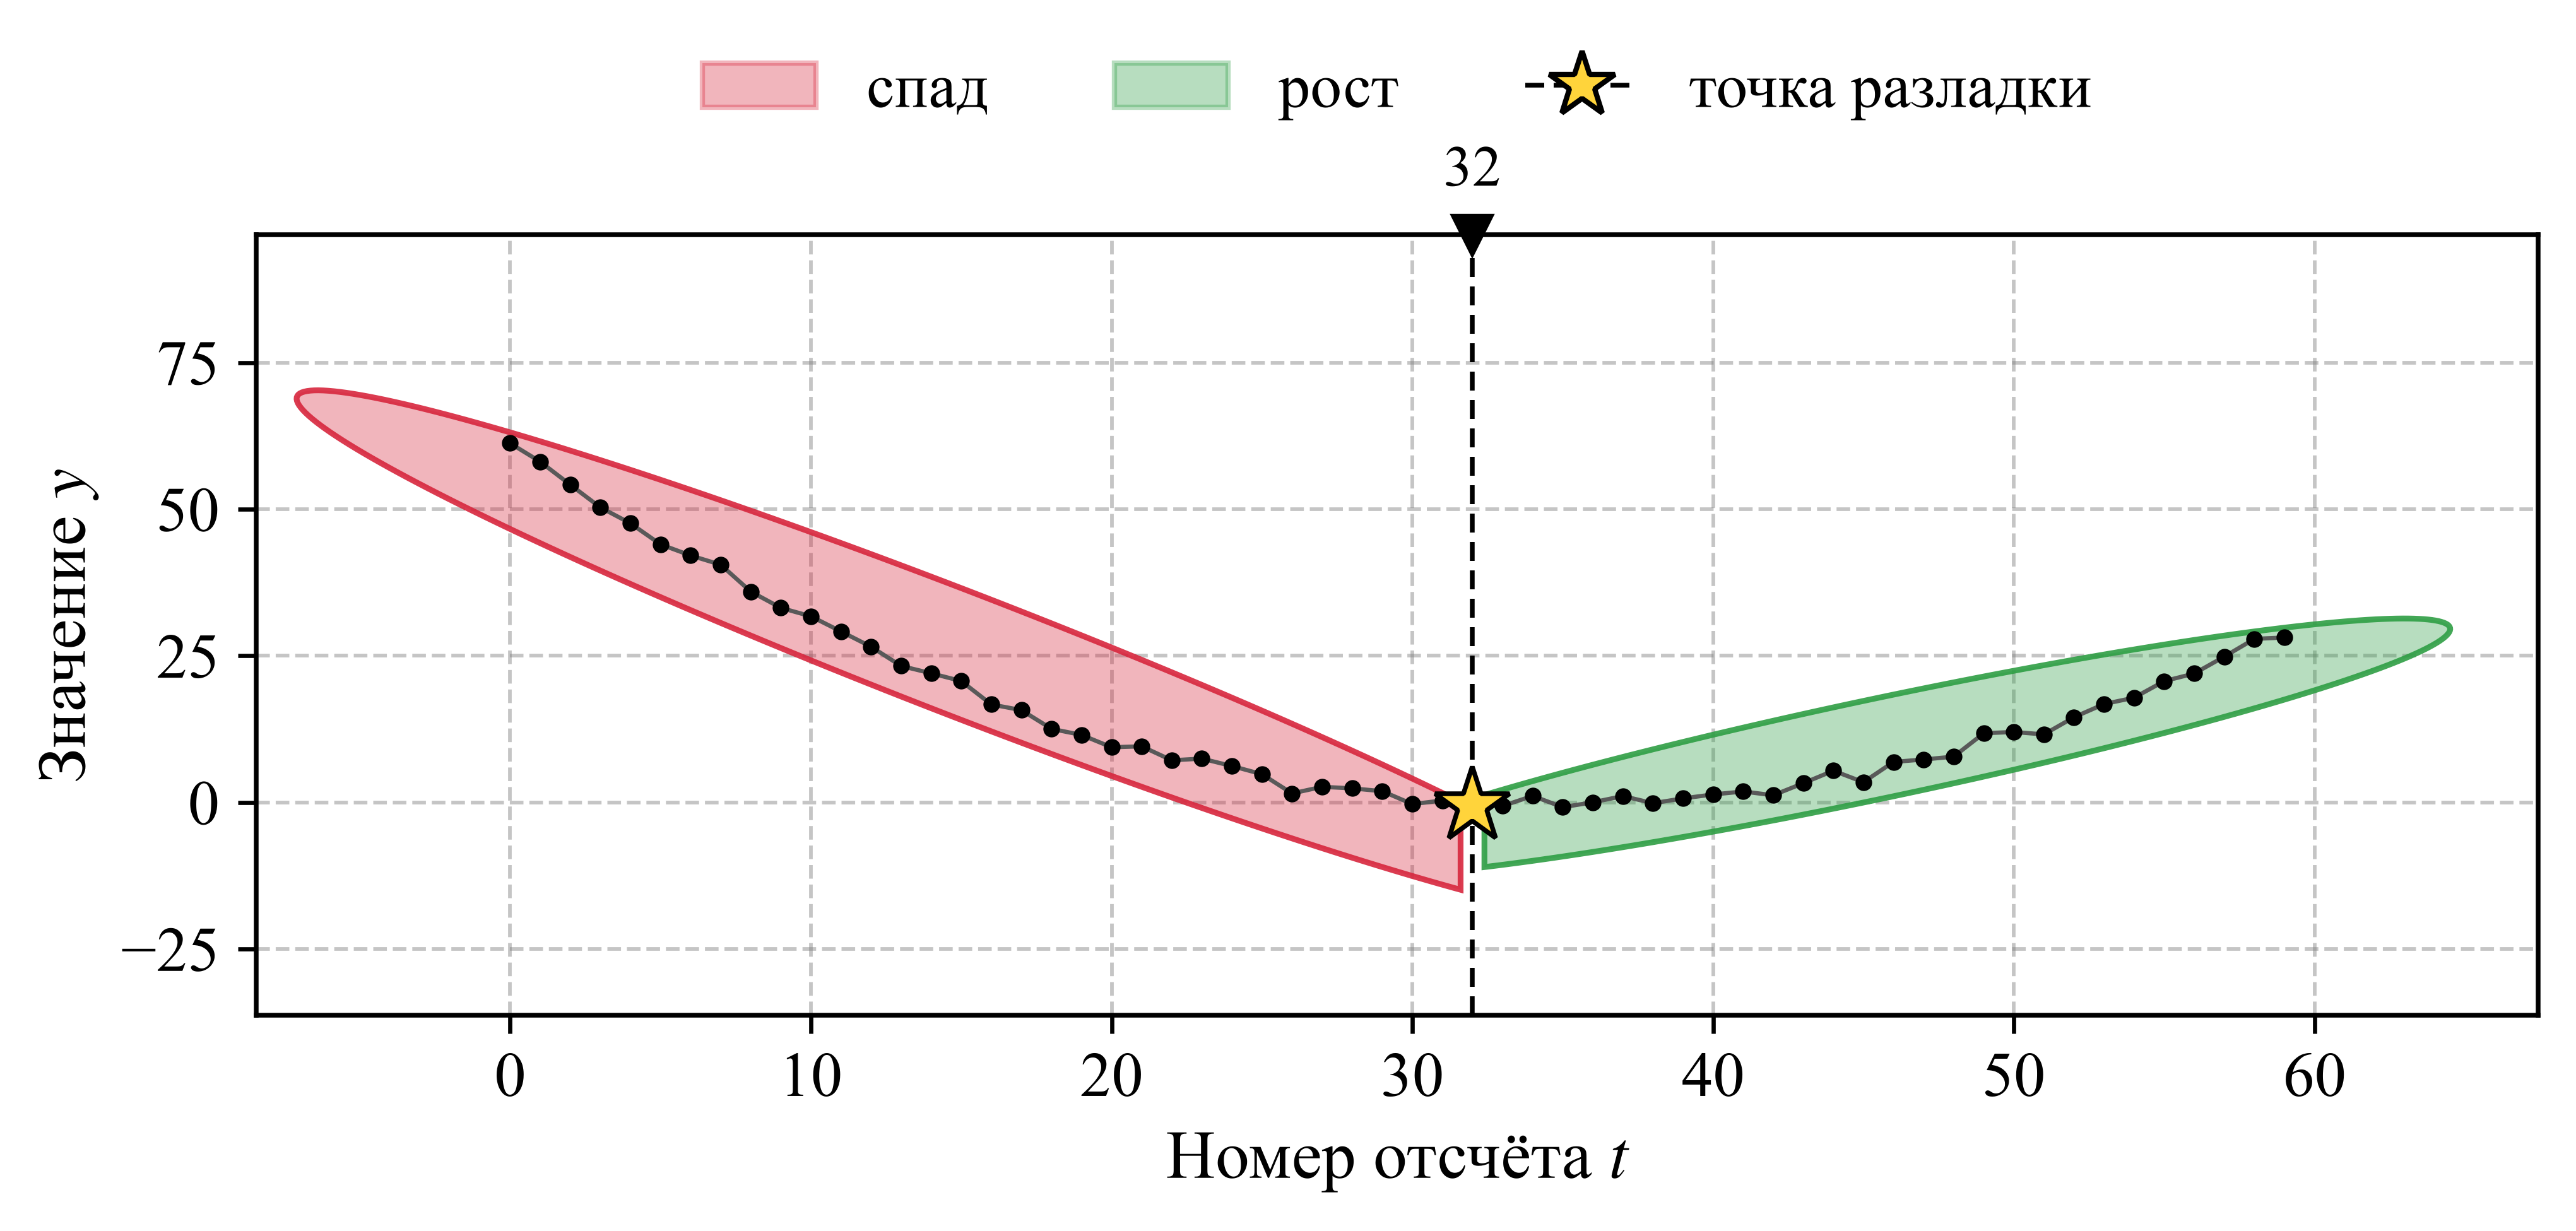

fig3_parabola: 4010x1879 px, 169.8x79.5 мм


In [3]:
rng = np.random.default_rng(7)
t = np.arange(60, dtype=float)
parabola = 0.05 * (t - 35) ** 2 + rng.normal(0, 1.0, t.size)
res_parabola = cluster_trends(parabola)
print(res_parabola.summary())
print("точки разладки:", [int(i) for i in boundary_points(res_parabola)])
print("линейных кусков до объединения:", len(res_parabola.pieces))
plot_clusters(res_parabola, "fig3_parabola")

## Рисунок 4. «Забор»

Ряд из 30 отсчётов, попеременно 0 и 1 с малым шумом $N(0;\ 0{,}05^2)$.
Знак первой разности меняется на каждом шаге, но устойчивого тренда нет.

30 points, 0 change point(s), noise std 1.184
  #0: [0, 30)   30 pts  flat  slope +0.0009378
без штрафа: 8 кластеров


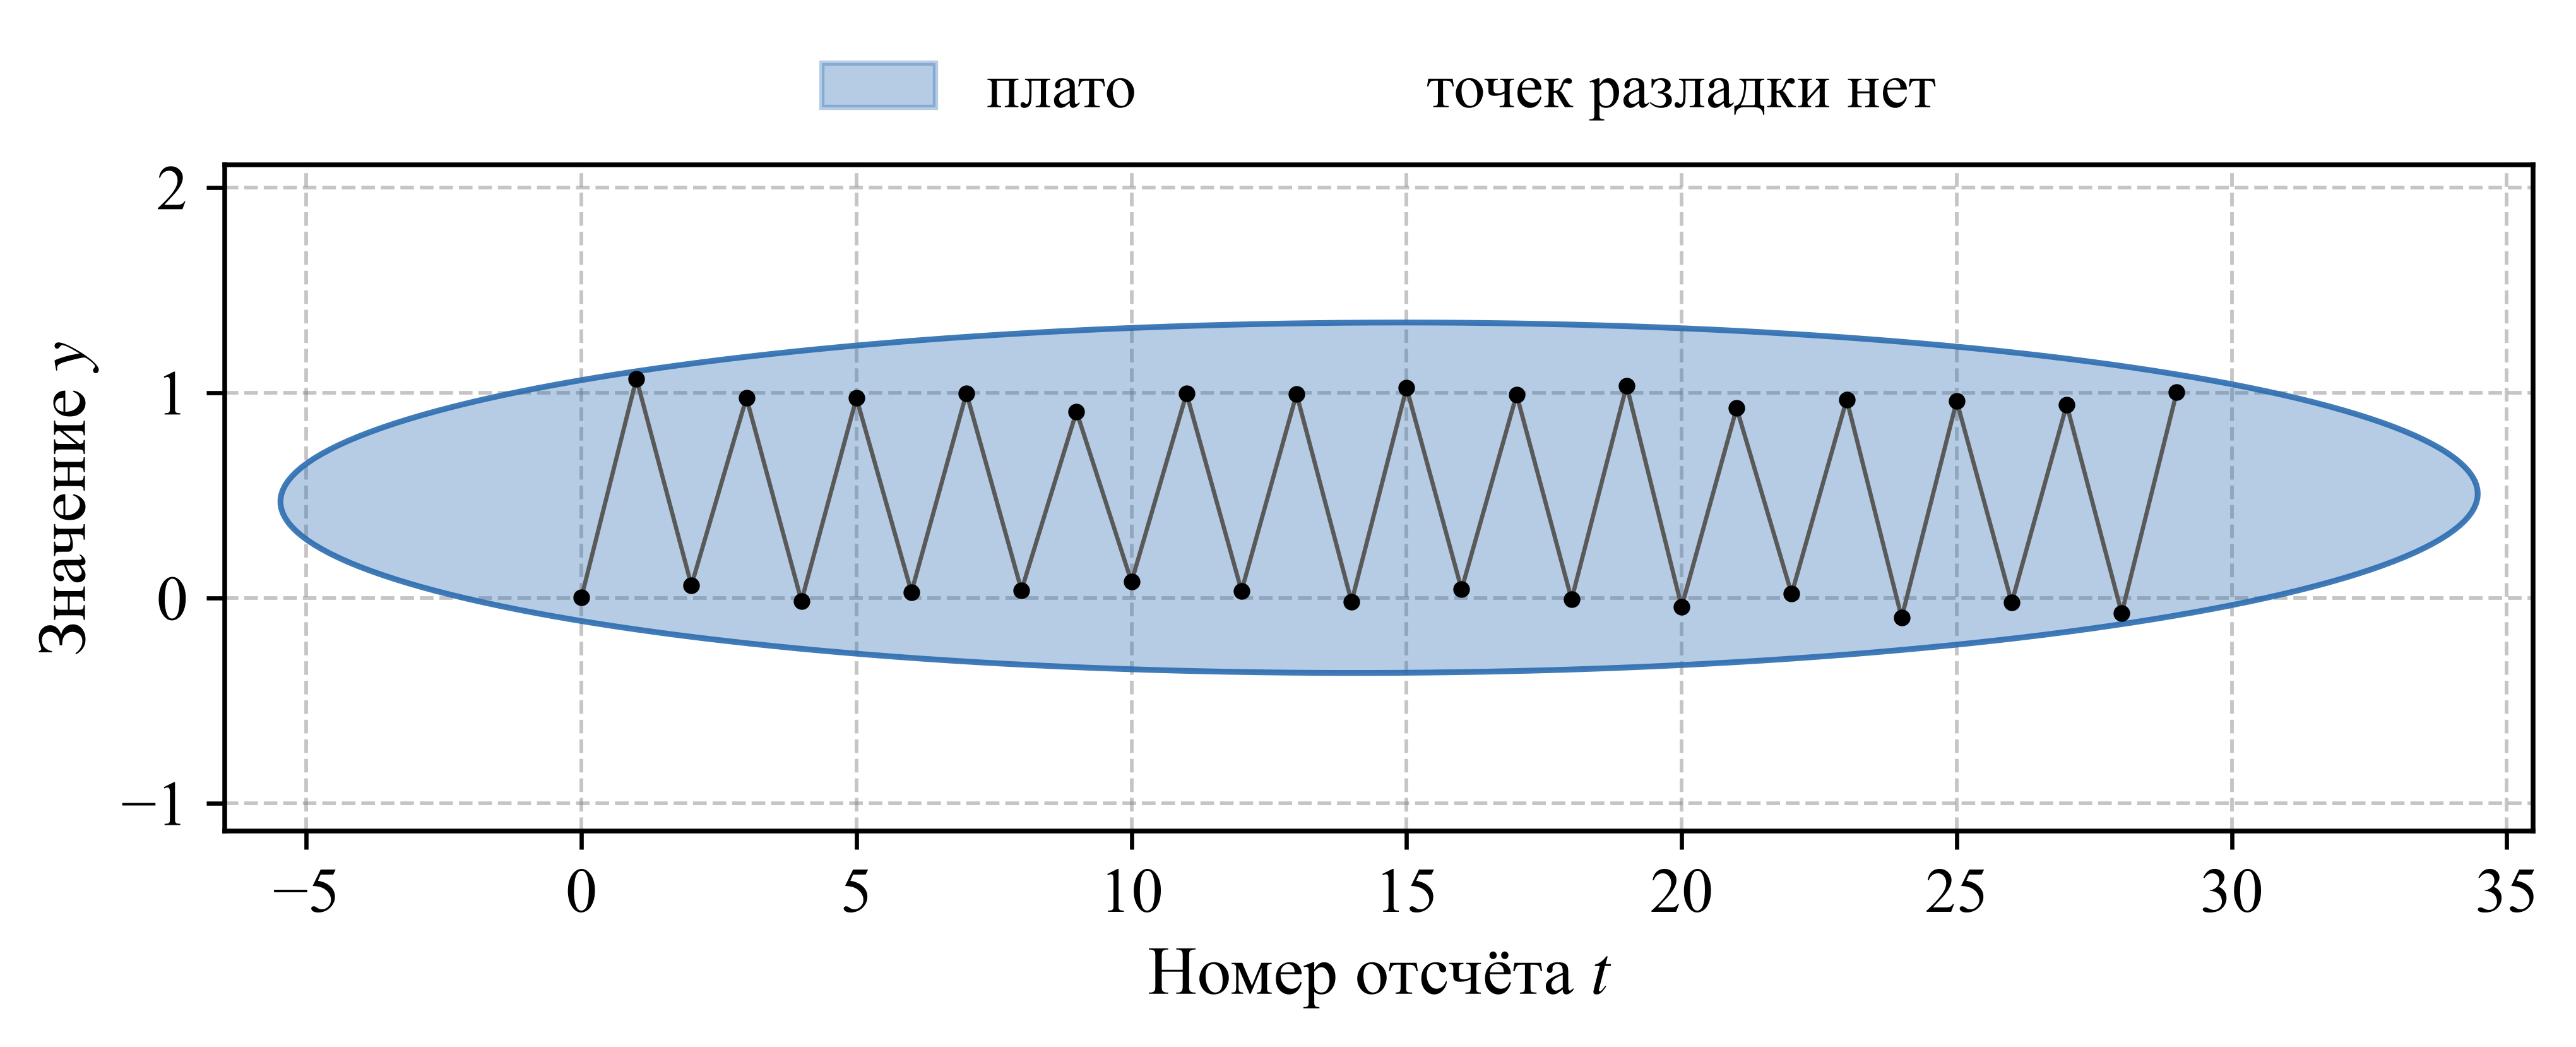

fig4_fence: 4009x1586 px, 169.7x67.1 мм


In [4]:
rng = np.random.default_rng(11)
fence = np.tile([0.0, 1.0], 15) + rng.normal(0, 0.05, 30)
res_fence = cluster_trends(fence)
print(res_fence.summary())
res_fence_none = cluster_trends(fence, penalty="none")
print("без штрафа:", res_fence_none.n_segments, "кластеров")
plot_clusters(res_fence, "fig4_fence", height_cm=5.8)

## Рисунок 5. Синусоида из пяти периодов

Ряд из 300 отсчётов $y_t = \sin(2\pi \cdot 5t/300) + \varepsilon_t$,
$\varepsilon_t \sim N(0;\ 0{,}15^2)$. Ожидаемое число монотонных участков 11:
четверть периода роста, девять полупериодов и снова четверть периода роста.

300 points, 10 change point(s), noise std 0.1539
  #0: [0, 20)   20 pts  up    slope +0.04689
  #1: [20, 45)   25 pts  down  slope -0.08167
  #2: [45, 76)   31 pts  up    slope +0.07681
  #3: [76, 105)   29 pts  down  slope -0.0842
  #4: [105, 136)   31 pts  up    slope +0.08196
  #5: [136, 164)   28 pts  down  slope -0.09
  #6: [164, 195)   31 pts  up    slope +0.07463
  #7: [195, 227)   32 pts  down  slope -0.07542
  #8: [227, 255)   28 pts  up    slope +0.08999
  #9: [255, 284)   29 pts  down  slope -0.08357
  #10: [284, 300)   16 pts  up    slope +0.07642
точки разладки: [19, 45, 76, 105, 136, 163, 195, 227, 255, 284]


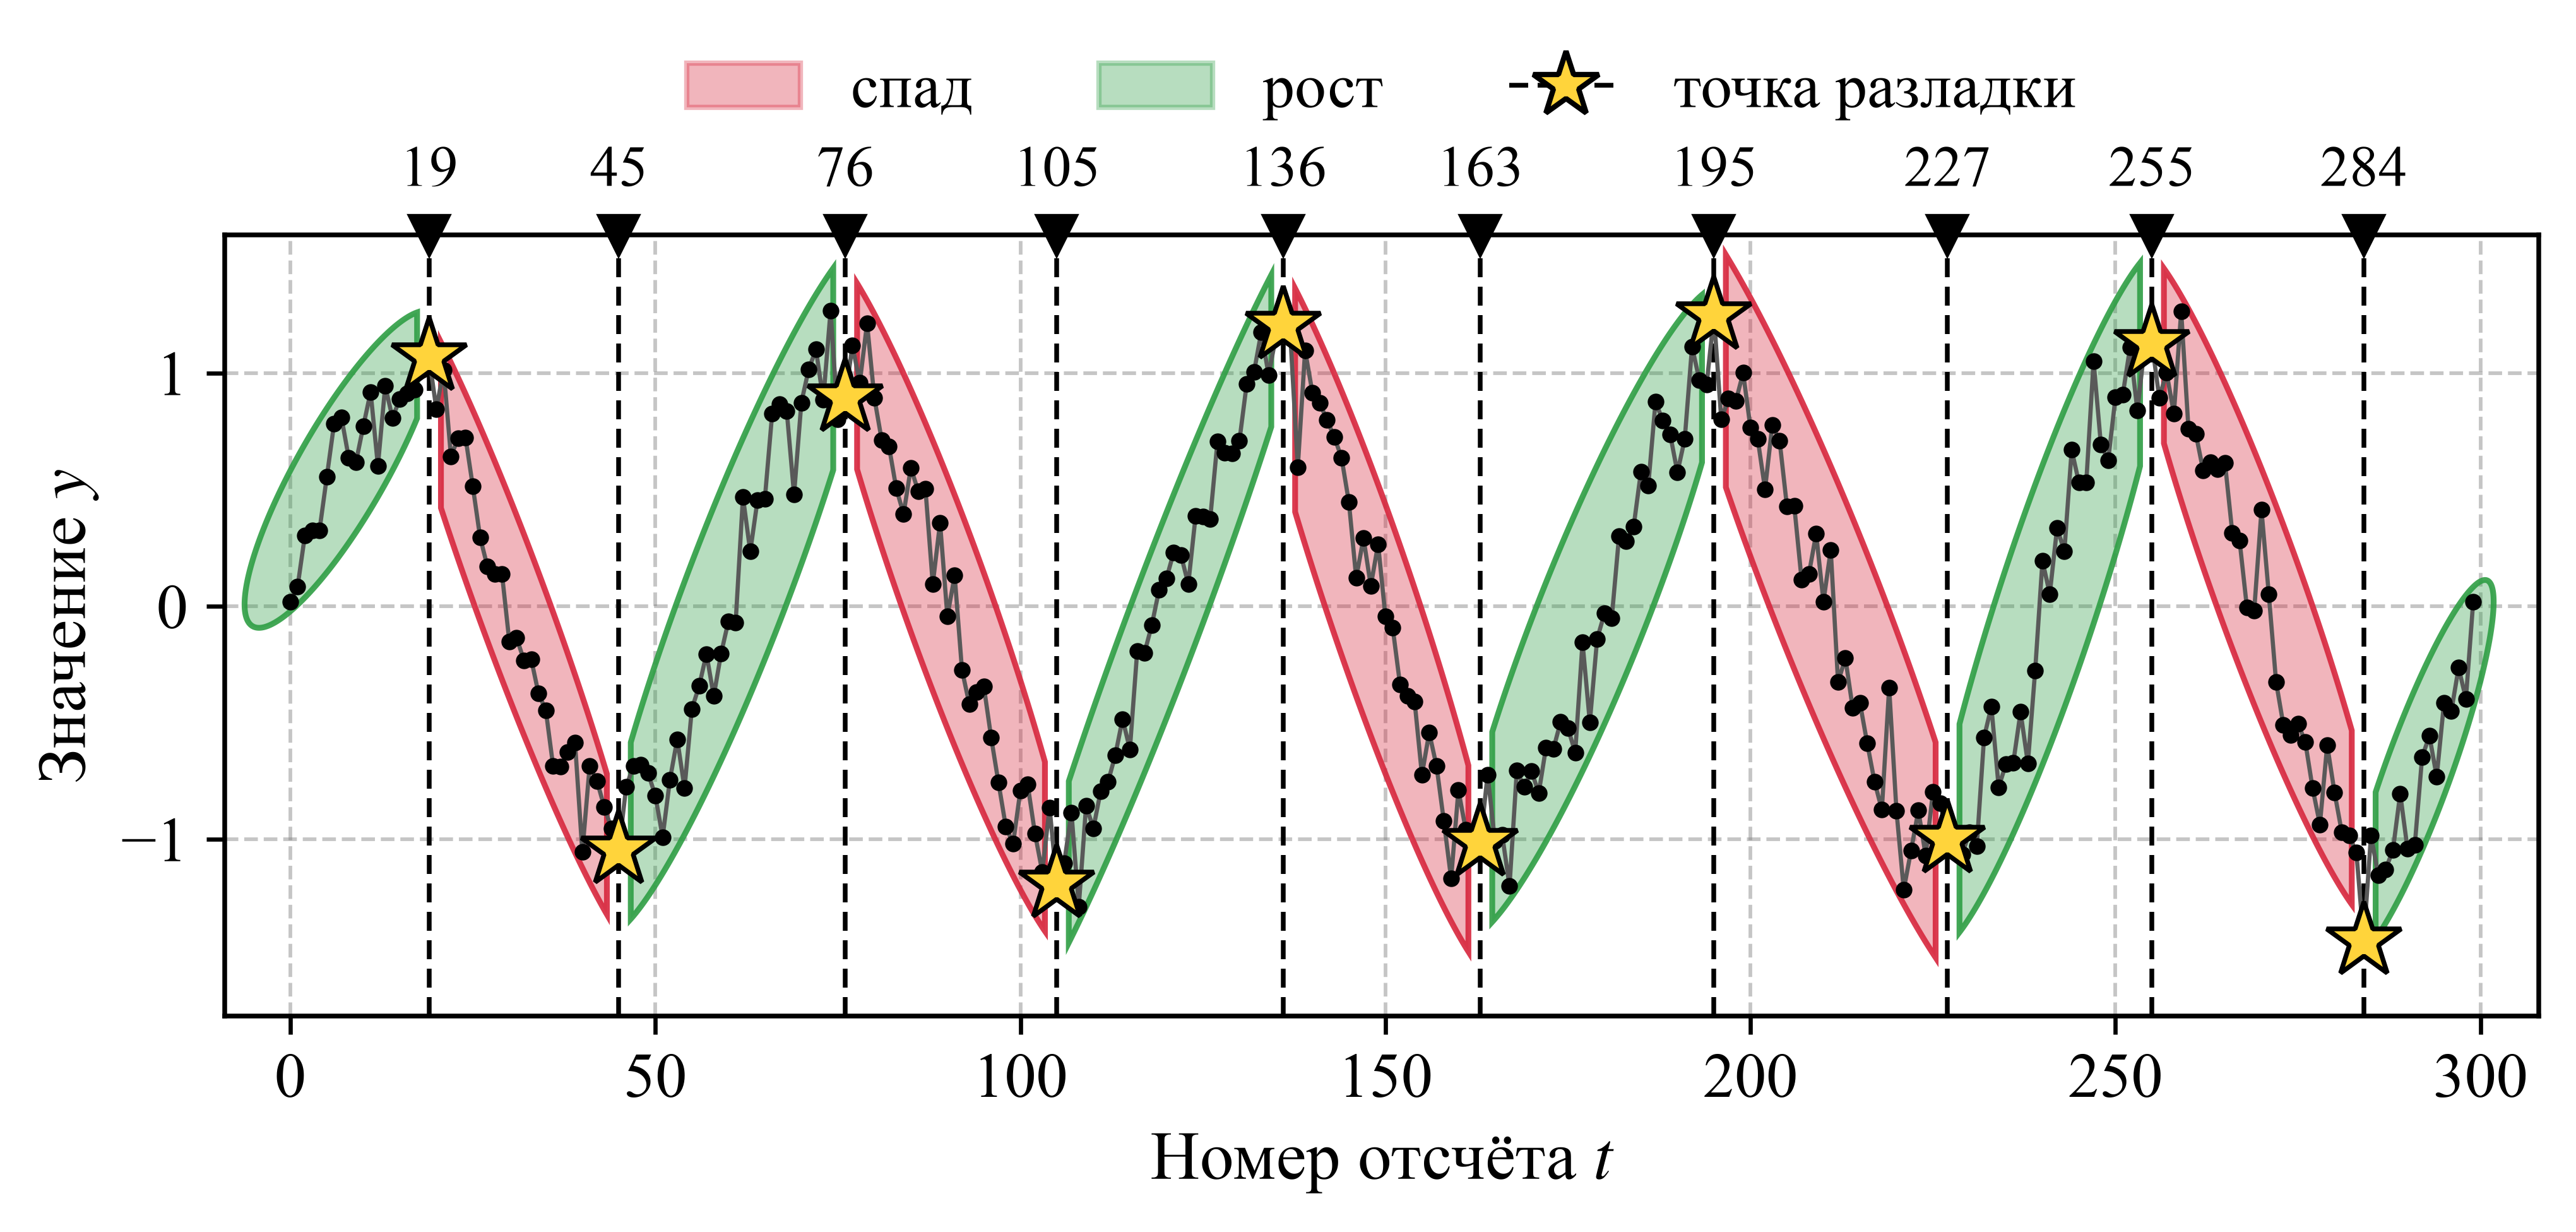

fig5_sine: 4009x1879 px, 169.7x79.5 мм


In [5]:
rng = np.random.default_rng(0)
t = np.arange(300, dtype=float)
sine = np.sin(2 * np.pi * 5 * t / 300) + rng.normal(0, 0.15, t.size)
res_sine = cluster_trends(sine)
print(res_sine.summary())
print("точки разладки:", [int(i) for i in boundary_points(res_sine)])
plot_clusters(res_sine, "fig5_sine")

## Таблица 1. Восстановление структуры кластеров

Для каждого типа ряда генерируется 200 реализаций шума. Разбиение считается
верным, если совпала последовательность меток кластеров, а граница (если она
есть) отклонилась от истинной не более чем на 10 % длины ряда.

In [6]:
R = 200


def scenario(kind, rng):
    if kind == "шум":
        y = rng.normal(0, 1, 100)
        return y, lambda r: r.n_segments == 1
    if kind == "забор":
        y = np.tile([0.0, 1.0], 15) + rng.normal(0, 0.05, 30)
        return y, lambda r: r.n_segments == 1
    if kind.startswith("V"):
        n, k, s = 100, 70, 1.0
        t = np.arange(n)
        y = np.where(t < k, -4 * t / k, -4 + 4 * (t - k) / (n - k)) + rng.normal(0, s, n)
        return y, lambda r: ([x.trend for x in r.segments] == [Trend.DOWN, Trend.UP]
                             and abs(r.change_points[0] - k) <= 0.1 * n)
    if kind.startswith("плато"):
        n, k = 100, 60
        s = 0.5 if "0.5" in kind else 1.0
        t = np.arange(n)
        y = np.where(t < k, 6 * t / k, 6.0) + rng.normal(0, s, n)
        return y, lambda r: ([x.trend for x in r.segments] == [Trend.UP, Trend.FLAT]
                             and abs(r.change_points[0] - k) <= 0.1 * n)
    if kind == "парабола":
        n = 80
        t = np.arange(n)
        y = 0.02 * (t - 50.0) ** 2 + rng.normal(0, 0.5, n)
        return y, lambda r: ([x.trend for x in r.segments] == [Trend.DOWN, Trend.UP]
                             and abs(r.change_points[0] - 50) <= 0.1 * n)
    if kind == "синусоида":
        n = 300
        t = np.arange(n)
        y = np.sin(2 * np.pi * 5 * t / n) + rng.normal(0, 0.15, n)

        def ok(r):
            ud = [x.trend for x in r.segments if x.trend is not Trend.FLAT]
            flat = sum(x.n_points for x in r.segments if x.trend is Trend.FLAT)
            return (len(ud) == 11 and all(a is not b for a, b in zip(ud, ud[1:]))
                    and flat <= 0.15 * n)
        return y, ok
    raise ValueError(kind)


KINDS = ["шум", "забор", "V", "плато σ=0.5", "плато σ=1", "парабола", "синусоида"]
METHODS = {
    "без штрафа": lambda y: cluster_trends(y, penalty="none", max_change_points=12),
    "линейный, 3 ln n (BIC)": lambda y: cluster_trends(
        y, penalty="linear", penalty_scale=3 * math.log(len(y))),
    "линейный, 6 ln n": lambda y: cluster_trends(
        y, penalty="linear", penalty_scale=6 * math.log(len(y))),
    "экспоненциальный, без объединения": lambda y: cluster_trends(y, merge_same_trend=False),
    "экспоненциальный (предлагаемый)": lambda y: cluster_trends(y),
}

start = time.perf_counter()
table1 = {}
for name, method in METHODS.items():
    row = []
    for kind in KINDS:
        hits = 0
        for seed in range(R):
            y, check = scenario(kind, np.random.default_rng(1000 + seed))
            hits += check(method(y))
        row.append(hits / R)
    table1[name] = row
    print(f"{name:36s}", "  ".join(f"{v:5.3f}" for v in row), flush=True)
print(f"время: {time.perf_counter() - start:.0f} с")

без штрафа                           0.000  0.000  0.000  0.000  0.000  0.030  0.990


линейный, 3 ln n (BIC)               0.935  1.000  0.845  0.750  0.450  0.605  0.940


линейный, 6 ln n                     1.000  1.000  0.880  0.780  0.455  0.805  1.000


экспоненциальный, без объединения    0.990  1.000  0.880  0.785  0.460  0.000  1.000


экспоненциальный (предлагаемый)      1.000  1.000  0.880  0.785  0.460  0.860  1.000


время: 488 с


## Таблица 2. Обучающая выборка для прогноза потребления памяти

Синтетический ряд потребления оперативной памяти (МБ) из 300 отсчётов
состоит из режимов длиной 30–89 отсчётов: рост или спад со скоростью
1–4 МБ на отсчёт либо постоянный уровень, плюс гауссов шум с СКО σ.
На каждом шаге по последним 100 отсчётам строится линейная регрессия и
прогноз на один шаг вперёд. Сравниваются четыре способа выбора обучающей
выборки: 5 последних отсчётов (как в базовой версии системы управления),
вся сохранённая история, последний трендовый кластер и последний линейный
кусок этого кластера.

In [7]:
def ram_series(rng, n, sigma):
    y, level, t, changes = np.empty(n), 2000.0, 0, []
    while t < n:
        length = int(rng.integers(30, 90))
        slope = rng.choice([0.0, rng.uniform(1, 4), -rng.uniform(1, 4)])
        for i in range(min(length, n - t)):
            level += slope
            y[t + i] = level
        t += length
        changes.append(t)
    return y + rng.normal(0, sigma, n), changes


def forecast(t, y, t_next):
    slope, intercept = np.polyfit(t, y, 1)
    return slope * t_next + intercept


HISTORY, RUNS, FIRST, N = 100, 30, 20, 300
WAYS = ["5 отсчётов", "вся история", "последний кластер", "последний кусок"]
start = time.perf_counter()
table2 = {}
for sigma in (5.0, 15.0, 30.0):
    errors = {w: {"переход": [], "режим": []} for w in WAYS}
    for seed in range(RUNS):
        y, changes = ram_series(np.random.default_rng(seed), N, sigma)
        tt = np.arange(N, dtype=float)
        for i in range(FIRST, N - 1):
            since = min(i + 1 - c for c in [0, *changes] if c <= i + 1)
            phase = "переход" if since < 10 else "режим"
            lo = max(0, i + 1 - HISTORY)
            th, yh = tt[lo:i + 1], y[lo:i + 1]
            res = cluster_trends(yh, t=th)
            samples = {
                "5 отсчётов": (th[-5:], yh[-5:]),
                "вся история": (th, yh),
                "последний кластер": res.select(),
                "последний кусок": res.select(level="piece"),
            }
            for way, (ts, ys) in samples.items():
                errors[way][phase].append(abs(forecast(ts, ys, i + 1) - y[i + 1]))
    table2[sigma] = errors
    for way in WAYS:
        both = errors[way]["переход"] + errors[way]["режим"]
        print(f"σ={sigma:4.0f}  {way:18s} MAE {np.mean(both):6.2f}   "
              f"переход {np.mean(errors[way]['переход']):6.2f}   "
              f"режим {np.mean(errors[way]['режим']):6.2f}", flush=True)
print(f"время: {time.perf_counter() - start:.0f} с")

σ=   5  5 отсчётов         MAE   5.67   переход   5.54   режим   5.70


σ=   5  вся история        MAE  22.32   переход  17.22   режим  23.26


σ=   5  последний кластер  MAE   6.62   переход   7.53   режим   6.45


σ=   5  последний кусок    MAE   4.83   переход   7.24   режим   4.39


σ=  15  5 отсчётов         MAE  16.97   переход  16.27   режим  17.10


...

σ=  30  5 отсчётов         MAE  33.93   переход  32.49   режим  34.20


σ=  30  вся история        MAE  33.84   переход  28.49   режим  34.83


σ=  30  последний кластер  MAE  27.68   переход  25.86   режим  28.02


σ=  30  последний кусок    MAE  27.36   переход  25.69   режим  27.66


время: 493 с


## Время работы

Время кластеризации одного ряда в зависимости от его длины.

In [8]:
rng = np.random.default_rng(5)
for n in (50, 100, 200, 500, 1000):
    y = np.cumsum(rng.normal(0, 1, n))
    reps = 20 if n <= 200 else 3
    start = time.perf_counter()
    for _ in range(reps):
        cluster_trends(y)
    print(f"n={n:5d}: {(time.perf_counter() - start) / reps * 1000:8.1f} мс")

n=   50:     16.5 мс


n=  100:     44.4 мс


n=  200:    189.1 мс


n=  500:    775.3 мс


n= 1000:   2260.2 мс
